# BIOT 6900 · Module 4 Assignment: Structure-Based Druggability of Your Targets

**Computational Lab 4 · 100 points · due Thursday, October 22 at 6:00 pm**

Apply the Module 4 lab skills to **two targets from your own Module 2 list**. Each step below matches a numbered step on the assignment sheet. Complete every cell marked **TODO**; helper functions from lab Part 2 and the demo are provided so you can focus on the analysis.

**Before you start:** complete lab Parts 1 and 2. Steps 2, 5 and 6 need internet. Step 6 needs **fpocket** (Mac/Linux: `conda install -c conda-forge fpocket`; Windows: run this notebook on the Explorer cluster).

**Run it in Jupyter or VS Code's notebook view**, not as a script. Before submitting: Kernel → Restart & Run All.

## Your settings (Step 1 · Choose two targets)

Pick two **protein-coding** targets from your Module 2 list, ideally **at least one with an experimental structure** (check the "Structure" section of the UniProt entry), each **shorter than 2,700 residues**.

For each target with a PDB structure, give the PDB ID and the chain to use. Use `None` if there is no experimental structure.

In [1]:
DISEASE = "luad"

TARGETS = {
    "FGFR2": "P21802",
    "CYP1A1": "P04798",
}
TARGET_INFO = {
    "FGFR2": {"module2_rank": 1, "why": "Top-ranked target across Module 2 and 3"},
    "CYP1A1": {"module2_rank": 8, "why": "Strong small-molecule tractability signal, mechanistic lung cancer link"},
}
PDB = {
    "FGFR2": ("3RI1", "A"),
    "CYP1A1": ("4I8V", "A"),
}

In [2]:
import json, shutil, subprocess, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

STRUCT = Path("structures"); STRUCT.mkdir(exist_ok=True)
assert set(TARGETS) == set(TARGET_INFO) == set(PDB), "TARGETS, TARGET_INFO and PDB must list the same genes"
if any(acc == "P00000" for acc in TARGETS.values()):
    raise ValueError("Set your two targets' UniProt accessions in the settings cell first.")

# ---------------- Helper functions (provided; from lab Part 2 and the demo) ----------------
def require(**kw):
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"Complete the TODO above: `{name}` is still `...`")

def download(url, path):
    if path.exists() and path.stat().st_size > 0:
        return path
    req = urllib.request.Request(url, headers={"User-Agent": "BIOT6900-course-notebook"})
    with urllib.request.urlopen(req, timeout=60) as r:
        path.write_bytes(r.read())
    return path

def fetch_alphafold(acc):
    pdb_path, pae_path = STRUCT / f"AF-{acc}.pdb", STRUCT / f"AF-{acc}-pae.json"
    if pdb_path.exists() and pae_path.exists():
        return pdb_path, pae_path
    urls = []
    try:
        req = urllib.request.Request(f"https://alphafold.ebi.ac.uk/api/prediction/{acc}",
                                     headers={"User-Agent": "BIOT6900-course-notebook"})
        with urllib.request.urlopen(req, timeout=60) as r:
            entry = json.loads(r.read())[0]
        urls.append((entry["pdbUrl"], entry["paeDocUrl"]))
    except Exception as e:
        print(f"  API lookup failed for {acc} ({type(e).__name__}); trying direct file names")
    for v in ("v6", "v4"):
        base = f"https://alphafold.ebi.ac.uk/files/AF-{acc}-F1"
        urls.append((f"{base}-model_{v}.pdb", f"{base}-predicted_aligned_error_{v}.json"))
    for pu, eu in urls:
        try:
            download(pu, pdb_path); download(eu, pae_path)
            return pdb_path, pae_path
        except Exception:
            continue
    raise RuntimeError(f"Could not download {acc}: download by hand from https://alphafold.ebi.ac.uk/entry/{acc}")

def read_pdb(path, chain=None):
    rows = []
    for line in open(path):
        if line.startswith(("ATOM", "HETATM")):
            if line[16] not in (" ", "A") or (chain and line[21] != chain):
                continue
            rows.append({"record": line[:6].strip(), "atom": line[12:16].strip(), "resname": line[17:20].strip(),
                         "chain": line[21], "resnum": int(line[22:26]), "icode": line[26].strip(),
                         "x": float(line[30:38]), "y": float(line[38:46]), "z": float(line[46:54]),
                         "b": float(line[60:66]) if line[60:66].strip() else 0.0, "element": line[76:78].strip()})
        elif line.startswith("ENDMDL"):
            break
    return pd.DataFrame(rows)

def load_pae(path):
    js = json.load(open(path)); js = js[0] if isinstance(js, list) else js
    if "predicted_aligned_error" in js:
        return np.array(js["predicted_aligned_error"], dtype=float)
    n = int(max(js["residue1"])); return np.array(js["distance"], dtype=float).reshape(n, n)

def band(v):
    return "Very high" if v > 90 else "Confident" if v > 70 else "Low" if v > 50 else "Very low"
BAND_COLOUR = {"Very high": "#0053D6", "Confident": "#65CBF3", "Low": "#FFDB13", "Very low": "#FF7D45"}

def runs_below(values, resnums, cut=50, min_len=10):
    out, start = [], None
    for i, flag in enumerate(np.append(np.asarray(values) < cut, False)):
        if flag and start is None: start = i
        elif not flag and start is not None:
            if i - start >= min_len: out.append(f"{resnums[start]}-{resnums[i-1]}")
            start = None
    return ", ".join(out) or "none"

def find_domains(pae, plddt, pae_cut=8, min_size=20):
    ok = np.where(np.asarray(plddt) >= 70)[0]
    sub = pae[np.ix_(ok, ok)]; linked = (sub < pae_cut) & (sub.T < pae_cut)
    label, cur = -np.ones(len(ok), int), 0
    for s0 in range(len(ok)):
        if label[s0] >= 0: continue
        stack = [s0]; label[s0] = cur
        while stack:
            k = stack.pop()
            for m in np.where(linked[k] & (label < 0))[0]:
                label[m] = cur; stack.append(m)
        cur += 1
    out = [(ok[label == c].min() + 1, ok[label == c].max() + 1, int((label == c).sum())) for c in range(cur) if (label == c).sum() >= min_size]
    return pd.DataFrame(out, columns=["start", "end", "confident_residues"])

THREE = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H",
         "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W",
         "TYR": "Y", "VAL": "V"}
def ca_table(df):
    ca = df[(df.atom == "CA") & (df.record == "ATOM")].drop_duplicates(["resnum", "icode"]).reset_index(drop=True)
    ca["aa"] = ca.resname.map(THREE).fillna("X")
    return ca

def global_align(a, b, match=2, mismatch=-1, gap=-2):
    # Needleman-Wunsch: list of (i, j) aligned index pairs
    n, m = len(a), len(b)
    S = np.zeros((n + 1, m + 1)); S[:, 0] = np.arange(n + 1) * gap; S[0, :] = np.arange(m + 1) * gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            S[i, j] = max(S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch), S[i-1, j] + gap, S[i, j-1] + gap)
    i, j, pairs = n, m, []
    while i > 0 and j > 0:
        if S[i, j] == S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch):
            pairs.append((i - 1, j - 1)); i -= 1; j -= 1
        elif S[i, j] == S[i-1, j] + gap: i -= 1
        else: j -= 1
    return pairs[::-1]

def kabsch(P, Q):
    # Rotation R and shift t so that P @ R + t best matches Q, plus the RMSD
    Pc, Qc = P.mean(0), Q.mean(0)
    U, S_, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    d = np.sign(np.linalg.det(U @ Vt)); R = U @ np.diag([1, 1, d]) @ Vt
    rmsd = float(np.sqrt((((P - Pc) @ R - (Q - Qc)) ** 2).sum(1).mean()))
    return R, Qc - Pc @ R, rmsd

def run_fpocket(pdb_path):
    out_dir = pdb_path.parent / f"{pdb_path.stem}_out"
    if not out_dir.exists():
        subprocess.run(["fpocket", "-f", str(pdb_path)], check=True, capture_output=True)
    pockets, cur = [], None
    for line in (out_dir / f"{pdb_path.stem}_info.txt").read_text().splitlines():
        if line.startswith("Pocket"):
            cur = {"pocket": int(line.split()[1])}; pockets.append(cur)
        elif cur is not None and ":" in line:
            key, val = [s.strip() for s in line.split(":", 1)]
            if key in ("Druggability Score", "Volume"): cur[key] = float(val)
    for p in pockets:
        p["lining_residues"] = sorted(read_pdb(out_dir / "pockets" / f"pocket{p['pocket']}_atm.pdb").resnum.unique().tolist())
    return pd.DataFrame(pockets)
print("Settings and helpers loaded for:", ", ".join(f"{g} ({a})" for g, a in TARGETS.items()))

Settings and helpers loaded for: FGFR2 (P21802), CYP1A1 (P04798)


## Step 2 · Download the AlphaFold model and PAE file

In [3]:
files, atoms, ca, pae = {}, {}, {}, {}
for gene, acc in TARGETS.items():
    files[gene] = fetch_alphafold(acc)
    atoms[gene] = read_pdb(files[gene][0])
    ca[gene] = ca_table(atoms[gene])
    pae[gene] = load_pae(files[gene][1])
    print(f"{gene} ({acc}): {len(ca[gene])} residues | PAE {pae[gene].shape}")

FGFR2 (P21802): 821 residues | PAE (821, 821)
CYP1A1 (P04798): 512 residues | PAE (512, 512)


## Step 3 · Read pLDDT

The plot is provided. **TODO:** build the summary table: mean pLDDT, % above 90, % below 50, and the stretches of 10+ residues below 50 (use `runs_below`).

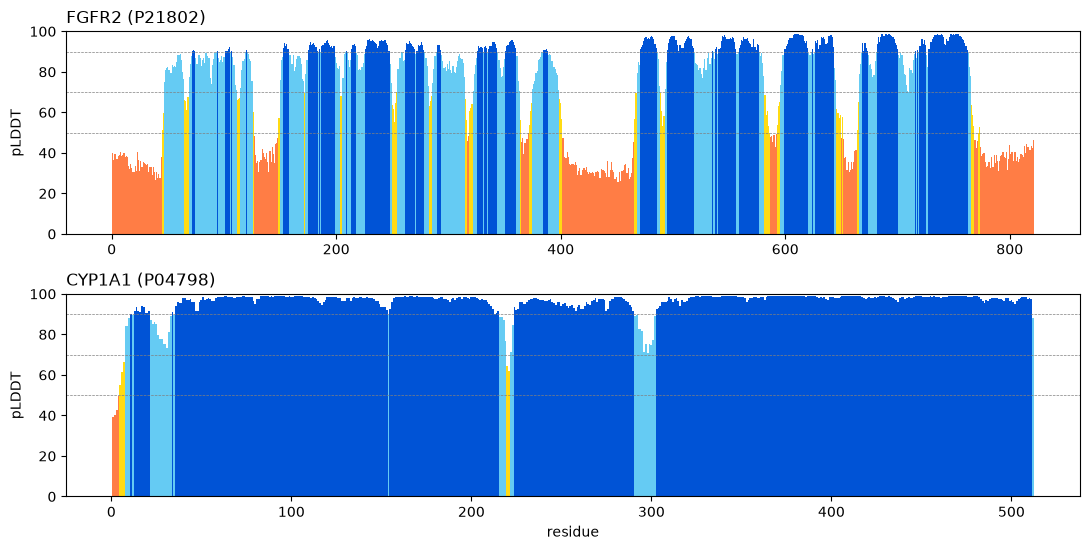

,gene,residues,mean_pLDDT,pct_above_90,pct_below_50,disordered_stretches
0,FGFR2,821,73.909367,36.297199,25.45676,"1-44, 127-148, 402-465, 652-663, 774-821"
1,CYP1A1,512,95.504746,91.015625,0.78125,none


In [4]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(11, 2.8 * len(TARGETS)), squeeze=False)
for ax, gene in zip(axes[:, 0], TARGETS):
    c = ca[gene]
    ax.bar(c.resnum, c.b, color=c.b.apply(band).map(BAND_COLOUR), width=1.0)
    for y in (50, 70, 90): ax.axhline(y, color="grey", lw=0.5, ls="--")
    ax.set_ylim(0, 100); ax.set_ylabel("pLDDT"); ax.set_title(f"{gene} ({TARGETS[gene]})", loc="left")
axes[-1, 0].set_xlabel("residue"); plt.tight_layout(); plt.show()

# TODO: one row per target with columns gene, residues, mean_pLDDT, pct_above_90, pct_below_50, disordered_stretches
plddt_summary = pd.DataFrame([{
    "gene": g,
    "residues": len(ca[g]),
    "mean_pLDDT": ca[g].b.mean(),
    "pct_above_90": (ca[g].b > 90).mean() * 100,
    "pct_below_50": (ca[g].b < 50).mean() * 100,
    "disordered_stretches": runs_below(ca[g].b.values, ca[g].resnum.values)
} for g in TARGETS])
require(plddt_summary=plddt_summary)
plddt_summary

## Step 4 · Read PAE and find domains

Heatmaps are provided. **TODO:** run `find_domains` for each target, and for any target with two or more domains compute the **mean PAE between the first two domains** (low = arrangement confident, high = uncertain).

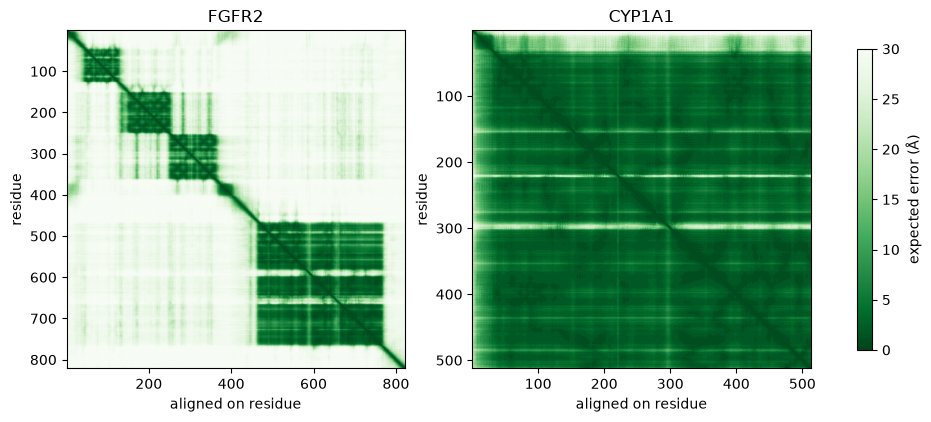


FGFR2: 5 confident domain(s); mean PAE between domains 1 and 2: 27.73481012658228 Å
 start  end  confident_residues
    47  125                  72
   150  249                  97
   255  363                  99
   375  398                  24
   468  765                 260

CYP1A1: 1 confident domain(s); mean PAE between domains 1 and 2: nan Å
 start  end  confident_residues
     8  512                 503


In [5]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4.6), squeeze=False)
for ax, gene in zip(axes[0], TARGETS):
    n = pae[gene].shape[0]
    im = ax.imshow(pae[gene], cmap="Greens_r", vmin=0, vmax=30, extent=[0.5, n + 0.5, n + 0.5, 0.5])
    ax.set_title(gene); ax.set_xlabel("aligned on residue"); ax.set_ylabel("residue")
plt.colorbar(im, ax=axes, label="expected error (Å)", shrink=0.85); plt.show()

domains, inter_pae = {}, {}
# TODO: fill domains[gene] with find_domains(...) and inter_pae[gene] with the mean PAE between
#       domain 1 and domain 2 (np.nan if fewer than two domains)
for g in TARGETS:
    domains[g] = find_domains(pae[g], ca[g].b.values)
    inter_pae[g] = pae[g][domains[g].iloc[0].start-1:domains[g].iloc[0].end, domains[g].iloc[1].start-1:domains[g].iloc[1].end].mean() if len(domains[g]) >= 2 else np.nan
for g in TARGETS:
    require(domains=domains[g], inter_pae=inter_pae[g])
    print(f"\n{g}: {len(domains[g])} confident domain(s); mean PAE between domains 1 and 2: {inter_pae[g]} Å")
    print(domains[g].to_string(index=False))

**In your report:** which regions would you trust for pocket analysis? Use the decision table (lecture slide 12).

## Step 5 · Compare with an experimental structure

For each target with a PDB entry: pair residues **by sequence alignment** (numbering often differs), superimpose on **identical, confident** pairs (pLDDT ≥ 70), and report the RMSD. If the target has two or more domains with high PAE between them, also report RMSD **per domain**.

In [6]:
comparison, deviation, exp_map = {}, {}, {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure; assess on confidence alone (say so in your report).")
        comparison[gene] = {"pdb_id": "none", "rmsd_confident": np.nan, "pairs_used": 0}
        continue
    pdb_id, chain = entry
    xt = read_pdb(download(f"https://files.rcsb.org/download/{pdb_id}.pdb", STRUCT / f"{pdb_id}.pdb"), chain=chain)
    xca, aca = ca_table(xt), ca[gene]
    pairs = global_align("".join(aca.aa), "".join(xca.aa))
    exp_map[gene] = {(xca.resnum[j], xca.icode[j]): aca.resnum[i] for i, j in pairs}   # PDB -> UniProt numbering
    A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()

    # TODO: keep only pairs where the amino acids match AND the AlphaFold pLDDT is >= 70,
    #       superimpose with kabsch, and store the RMSD
    use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
    R, t, rmsd = kabsch(A[[i for i, _ in use]], X[[j for _, j in use]])
    require(use=use, rmsd=rmsd)
    moved = A @ R + t
    deviation[gene] = pd.Series({aca.resnum[i]: float(np.linalg.norm(moved[i] - X[j])) for i, j in use})
    comparison[gene] = {"pdb_id": pdb_id, "rmsd_confident": round(rmsd, 2), "pairs_used": len(use)}
    print(f"{gene} vs {pdb_id} chain {chain}: {len(pairs)} aligned pairs, {len(use)} identical and confident; RMSD {rmsd:.2f} Å")

    # Per-domain RMSD when the arrangement between domains is uncertain
    if len(domains[gene]) >= 2 and inter_pae[gene] > 10:
        for k, d in domains[gene].iterrows():
            sub = [(i, j) for i, j in use if d.start <= aca.resnum[i] <= d.end]
            if len(sub) >= 10:
                print(f"   domain {k + 1} ({d.start}-{d.end}): RMSD {kabsch(A[[i for i, _ in sub]], X[[j for _, j in sub]])[2]:.2f} Å over {len(sub)} residues")

FGFR2 vs 3RI1 chain A: 285 aligned pairs, 256 identical and confident; RMSD 0.65 Å
   domain 5 (468-765): RMSD 0.65 Å over 256 residues
CYP1A1 vs 4I8V chain A: 477 aligned pairs, 475 identical and confident; RMSD 0.33 Å


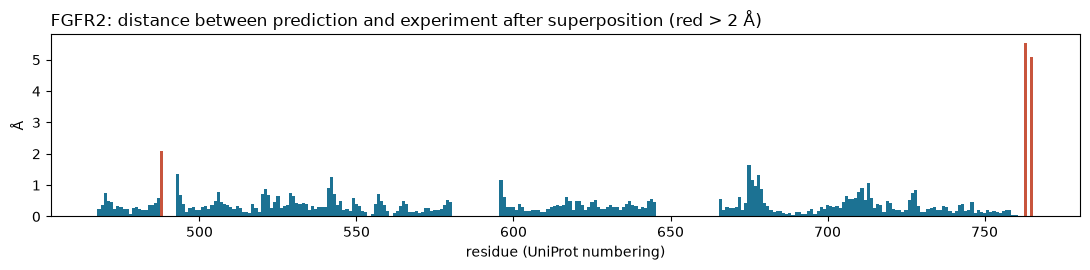

FGFR2: residues that differ most: 763 (5.5 Å), 765 (5.1 Å), 488 (2.1 Å), 675 (1.7 Å), 493 (1.3 Å), 678 (1.3 Å)


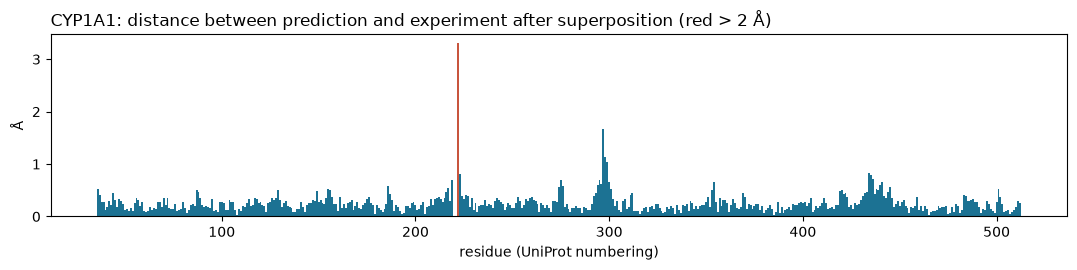

CYP1A1: residues that differ most: 222 (3.3 Å), 297 (1.7 Å), 298 (1.1 Å), 299 (1.0 Å), 434 (0.8 Å), 223 (0.8 Å)


In [7]:
for gene, dev in deviation.items():
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.bar(dev.index, dev.values, color=["#C8553D" if d > 2 else "#1C7293" for d in dev.values], width=1.0)
    ax.set_title(f"{gene}: distance between prediction and experiment after superposition (red > 2 Å)", loc="left")
    ax.set_xlabel("residue (UniProt numbering)"); ax.set_ylabel("Å"); plt.tight_layout(); plt.show()
    print(f"{gene}: residues that differ most:", ", ".join(f"{r} ({v:.1f} Å)" for r, v in dev.nlargest(6).items()))

## Step 6 · Detect and filter pockets

**TODO:** for each pocket, compute the mean pLDDT of the lining residues and the mean PAE among them, then apply the rules: **reject** if mean pLDDT < 70; **suspect** if PAE among the lining residues > 10 Å; otherwise **keep**. Show the top five by druggability score. Every pocket is kept (with its **rank** by score) for the ligand-site check below.

In [9]:
if shutil.which("fpocket") is None:
    raise RuntimeError("fpocket not found. Mac/Linux: conda install -c conda-forge fpocket, then restart the kernel. "
                       "Windows: run this notebook on the Explorer cluster.")
top_pockets, all_pockets = {}, {}
for gene in TARGETS:
    pk = run_fpocket(files[gene][0])
    plddt = ca[gene].set_index("resnum").b
    # TODO: add columns mean_pLDDT, PAE_within and verdict to pk
    pk["mean_pLDDT"] = pk["lining_residues"].apply(lambda r: plddt.reindex(r).mean())
    pk["PAE_within"] = pk["lining_residues"].apply(lambda r: pae[gene][np.ix_([x-1 for x in r], [x-1 for x in r])].mean())
    pk["verdict"] = np.where(pk["mean_pLDDT"] < 70, "reject", np.where(pk["PAE_within"] > 10, "suspect", "keep"))
    require(verdict=pk["verdict"].iloc[0])
    pk["rank"] = pk["Druggability Score"].rank(ascending=False, method="first").astype(int)
    all_pockets[gene] = pk
    top_pockets[gene] = pk.sort_values("Druggability Score", ascending=False).head(5)
    print(f"\n{gene}: top five pockets by druggability score")
    print(top_pockets[gene].drop(columns="lining_residues").to_string(index=False))


FGFR2: top five pockets by druggability score
 pocket  Druggability Score   Volume  mean_pLDDT  PAE_within verdict  rank
     50               0.882 2219.878   77.536042    7.351997    keep     1
     60               0.386 1106.104   62.960455   12.464876  reject     2
     43               0.069  262.227   67.524444    8.395062  reject     3
     11               0.044  279.056   87.083333    1.222222    keep     4
     42               0.017  516.061   72.247273   13.727273 suspect     5

CYP1A1: top five pockets by druggability score
 pocket  Druggability Score   Volume  mean_pLDDT  PAE_within verdict  rank
      1               0.991 1383.240   96.728222    1.955556    keep     1
      3               0.005  216.763   90.724000    1.000000    keep     2
     18               0.003  334.377   94.464444    1.358025    keep     3
     14               0.002  439.298   98.558667    1.222222    keep     4
     27               0.001  393.052   91.492222    2.592593    keep    13


### Ligand-site check *(provided)*

**If your experimental structure has a ligand bound,** the next cell takes **each** bound ligand in turn, finds the protein residues within 4.5 Å of it, converts them to UniProt numbering using your Step 5 alignment, and searches **every** pocket, not just the top five. For each ligand it reports how much of the site your best kept pocket covers, and which pocket covers it best, with that pocket's rank, score and verdict.

**In your report:** is your best **kept** pocket where the ligand sits? If there are several copies of a ligand, which one is in the functional site? If not, which pocket is, how does it rank, and why might fpocket score a real binding site low? (Large, open or polar sites, such as protease clefts, often score poorly.)

*Not counted as ligands:* water, metal ions, common crystallization additives (sulfate, glycerol and similar), and peptide or nucleic-acid partners deposited as a separate protein or DNA chain.

In [10]:
IGNORE_HET = {"HOH", "WAT", "DOD", "SO4", "PO4", "GOL", "EDO", "PEG", "PG4", "PGE", "1PE", "ACT", "FMT", "DMS",
              "MPD", "BME", "TRS", "EPE", "MES", "IMD", "CL", "NA", "K", "MG", "CA", "ZN", "MN", "FE", "CU", "CO",
              "NI", "CD", "HG", "IOD", "BR", "NO3", "NH4", "SCN", "UNX"}

def ligand_sites(pdb_path, chain, cutoff=4.5, min_atoms=6):
    """For each small-molecule ligand touching `chain`: the (resnum, icode) of chain residues within `cutoff` Å."""
    at = read_pdb(pdb_path)
    het = at[(at.record == "HETATM") & ~at.resname.isin(IGNORE_HET)]
    het = het[het.groupby(["chain", "resname", "resnum"]).x.transform("size") >= min_atoms]   # drop ions / tiny additives
    prot = at[(at.record == "ATOM") & (at.chain == chain)]
    sites = {}
    for (c, name, num), lig in het.groupby(["chain", "resname", "resnum"]):
        d = np.linalg.norm(prot[["x", "y", "z"]].to_numpy()[:, None] - lig[["x", "y", "z"]].to_numpy()[None], axis=2)
        near = (d < cutoff).any(1)
        if near.any():
            sites[f"{name} {c}{num}"] = set(zip(prot.resnum[near], prot.icode[near]))
    return sites

ligand_pockets = {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure, so no ligand-site check.\n"); continue
    pdb_id, chain = entry
    sites = ligand_sites(STRUCT / f"{pdb_id}.pdb", chain)
    if not sites:
        print(f"{gene}: {pdb_id} chain {chain} has no bound small-molecule ligand to check against.\n"); continue
    pk = all_pockets[gene]
    kept = pk[pk.verdict == "keep"].sort_values("Druggability Score", ascending=False)
    best = kept.iloc[0] if len(kept) else None
    rows = []
    for lig, contacts in sites.items():
        site = sorted({exp_map[gene][k] for k in contacts if k in exp_map[gene]})   # UniProt numbering
        if not site:
            print(f"  {lig}: its contact residues are not in the aligned region; skipped"); continue
        cover = pk.lining_residues.apply(lambda r: len(set(r) & set(site)) / len(site))
        top = pk.loc[cover.idxmax()]
        rows.append({"ligand": lig, "site_residues": len(site),
                     "best_kept_pocket_covers": round(float(cover[best.name]), 2) if best is not None else np.nan,
                     "site_pocket": int(top.pocket), "site_pocket_rank": int(top["rank"]),
                     "site_pocket_score": round(top["Druggability Score"], 3), "site_pocket_verdict": top.verdict,
                     "site_pocket_covers": round(float(cover.max()), 2), "residues": ", ".join(map(str, site))})
    ligand_pockets[gene] = pd.DataFrame(rows)
    print(f"{gene} vs {pdb_id} chain {chain}  |  best kept pocket: "
          + (f"{int(best.pocket)} (score {best['Druggability Score']:.3f}, rank {int(best['rank'])})" if best is not None else "none"))
    print(ligand_pockets[gene].drop(columns="residues").to_string(index=False))
    for r in rows:
        print(f"  {r['ligand']} site (UniProt numbering): {r['residues']}")
    print()


FGFR2 vs 3RI1 chain A  |  best kept pocket: 50 (score 0.882, rank 1)
ligand  site_residues  best_kept_pocket_covers  site_pocket  site_pocket_rank  site_pocket_score site_pocket_verdict  site_pocket_covers
3RH A2             16                      1.0           50                 1              0.882                keep                 1.0
  3RH A2 site (UniProt numbering): 487, 488, 495, 515, 517, 534, 538, 548, 564, 565, 566, 567, 570, 633, 643, 644

CYP1A1 vs 4I8V chain A  |  best kept pocket: 1 (score 0.991, rank 1)
  ligand  site_residues  best_kept_pocket_covers  site_pocket  site_pocket_rank  site_pocket_score site_pocket_verdict  site_pocket_covers
BHF A602             16                     0.94            1                 1              0.991                keep                0.94
HEM A601             29                     0.93            1                 1              0.991                keep                0.93
  BHF A602 site (UniProt numbering): 115, 116, 123, 222,

## Step 7 · Make a druggability call and export the summary

Choose one call per target: **"Structure supports a small-molecule pocket"**, **"Possible but uncertain"**, or **"No confident pocket: consider another modality"**. Justify it in your report.

In [12]:
CALLS = {
    "FGFR2": "Structure supports a small-molecule pocket",
    "CYP1A1": "Structure supports a small-molecule pocket",
}
assert set(CALLS) == set(TARGETS), "Give a call for every target"

rows = []
for g, acc in TARGETS.items():
    kept = top_pockets[g][top_pockets[g].verdict == "keep"]
    rows.append({"gene": g, "uniprot": acc, "module2_rank": TARGET_INFO[g]["module2_rank"],
                 "mean_pLDDT": plddt_summary.set_index("gene").loc[g, "mean_pLDDT"],
                 "pct_below_50": plddt_summary.set_index("gene").loc[g, "pct_below_50"],
                 "n_domains": len(domains[g]), "inter_domain_PAE": inter_pae[g],
                 "pdb_id": comparison[g]["pdb_id"], "rmsd_confident": comparison[g]["rmsd_confident"],
                 "best_pocket_score": round(kept["Druggability Score"].max(), 3) if len(kept) else np.nan,
                 "best_pocket_verdict": "keep" if len(kept) else top_pockets[g].verdict.iloc[0],
                 "druggability_call": CALLS[g]})
summary = pd.DataFrame(rows)
out_file = f"structure_assessment_{DISEASE}.csv"
summary.to_csv(out_file, index=False)
print("Wrote", out_file)
summary

Wrote structure_assessment_luad.csv


,gene,uniprot,module2_rank,mean_pLDDT,pct_below_50,n_domains,inter_domain_PAE,pdb_id,rmsd_confident,best_pocket_score,best_pocket_verdict,druggability_call
0,FGFR2,P21802,1,73.909367,25.45676,5,27.73481,3RI1,0.65,0.882,keep,Structure supports a small-molecule pocket
1,CYP1A1,P04798,8,95.504746,0.78125,1,NaN,4I8V,0.33,0.991,keep,Structure supports a small-molecule pocket


In [13]:
import os
print(os.path.abspath("structure_assessment_luad.csv"))

/Users/bhavadharanin/Downloads/structure_assessment_luad.csv


**FGFR2 structure**

In [3]:
import py3Dmol

with open('../../structures/AF-P21802.pdb') as f:
    pdb_data = f.read()

view = py3Dmol.view(width=800, height=600)
view.addModel(pdb_data, 'pdb')
view.setStyle({'cartoon': {'colorscheme': {'prop': 'b', 'gradient': 'roygb', 'min': 50, 'max': 90}}})

pocket_residues = [487,488,495,515,517,534,538,548,564,565,566,567,570,633,643,644]
view.addStyle({'resi': pocket_residues}, {'stick': {'color': 'yellow'}})

view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**CYP1A1 Structure**

In [4]:
with open('../../structures/AF-P04798.pdb') as f:
    pdb_data2 = f.read()

view2 = py3Dmol.view(width=800, height=600)
view2.addModel(pdb_data2, 'pdb')
view2.setStyle({'cartoon': {'colorscheme': {'prop': 'b', 'gradient': 'roygb', 'min': 50, 'max': 90}}})

pocket_residues2 = [115,116,123,222,224,255,258,312,313,316,317,319,320,321,386,496]
view2.addStyle({'resi': pocket_residues2}, {'stick': {'color': 'yellow'}})

view2.zoomTo()
view2.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.